# 3-Qubit Bit-Flip Code

Encodes α|0⟩ + β|1⟩ as α|000⟩ + β|111⟩, then flips one qubit (X error).
Two ancillas measure the parities q0⊕q1 and q1⊕q2. This **syndrome** locates
the error without disturbing the superposition:

| Syndrome (c1 c0) | 00 | 01 | 11 | 10 |
|---|---|---|---|---|
| Flipped qubit | none | q[0] | q[1] | q[2] |

An X gate on that qubit corrects it, and decoding returns the state to q[0].

**Inputs:** amplitudes a and b (normalized automatically) and the error qubit (0, 1 or 2).
The second cell saves the circuit diagram as a PNG.

Enter amplitude a :  0.8
Enter amplitude b :  0.6



Original input state:
((0.8+0j))|0> + ((0.6+0j))|1>



Enter error qubit (0, 1, or 2):  2



Error detection result:
Error detected in q[2].
X gate applied to q[2].

Original state:
((0.8+0j))|0> + ((0.6+0j))|1>

Recovered state after error correction:
((0.8+0j))|0> + ((0.6+0j))|1>

Quantum Circuit:


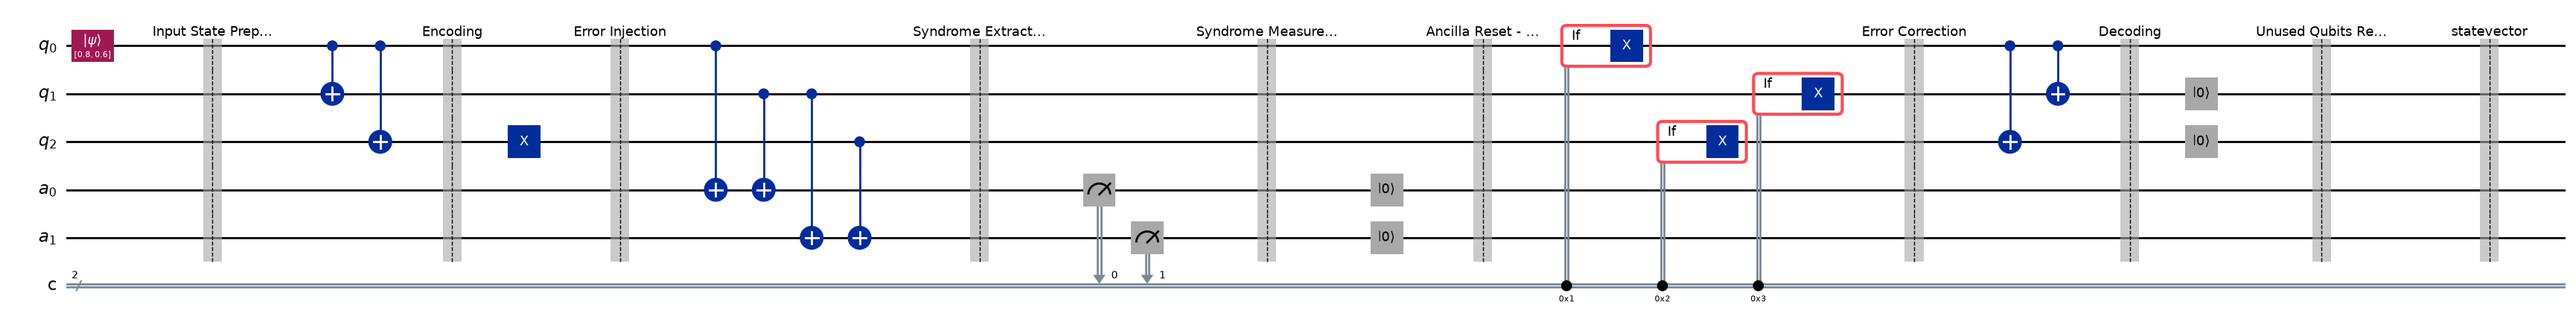

In [17]:

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator
import numpy as np

# Registers
q = QuantumRegister(3, 'q')
a = QuantumRegister(2, 'a')
c = ClassicalRegister(2, 'c')

qc = QuantumCircuit(q, a, c)

# Input state: alpha|0> + beta|1>
alpha = complex(input("Enter amplitude a : "))
beta = complex(input("Enter amplitude b : "))

# Normalize input state
norm = np.sqrt(abs(alpha)**2 + abs(beta)**2)

if norm == 0:
    raise ValueError("Input state cannot have both amplitudes zero.")

alpha = alpha / norm
beta = beta / norm

# Initialize quantum state
qc.initialize([alpha, beta], q[0])
qc.barrier(label="Input State Preparation")

print("\nOriginal input state:")
print(f"({alpha})|0> + ({beta})|1>")

# ---------- Encoding ----------
qc.cx(q[0], q[1])
qc.cx(q[0], q[2])
qc.barrier(label="Encoding")

# ---------- Error Injection ----------
error_bit = int(input("\nEnter error qubit (0, 1, or 2): "))

if error_bit not in [0, 1, 2]:
    raise ValueError("Enter only 0, 1, or 2.")

qc.x(q[error_bit])
qc.barrier(label="Error Injection")

# ---------- Syndrome Extraction ----------
qc.cx(q[0], a[0])
qc.cx(q[1], a[0])
qc.cx(q[1], a[1])
qc.cx(q[2], a[1])
qc.barrier(label="Syndrome Extraction")

# ---------- Syndrome Measurement ----------
qc.measure(a[0], c[0])
qc.measure(a[1], c[1])
qc.barrier(label="Syndrome Measurement")

# Ancilla reset
qc.reset(a[0])
qc.reset(a[1])
qc.barrier(label="Ancilla Reset - Available for Reuse")

# ---------- Error Correction ----------
with qc.if_test((c, 1)):
    qc.x(q[0])

with qc.if_test((c, 2)):
    qc.x(q[2])

with qc.if_test((c, 3)):
    qc.x(q[1])

qc.barrier(label="Error Correction")

# ---------- Decoding ----------
qc.cx(q[0], q[2])
qc.cx(q[0], q[1])
qc.barrier(label="Decoding")

# ---------- Reset Unused Data Qubits ----------
qc.reset(q[1])
qc.reset(q[2])
qc.barrier(label="Unused Qubits Reset - Available for Reuse")

# ---------- Final Recovered State ----------
qc.save_statevector()

# ---------- Run Simulation ----------
backend = AerSimulator(method="statevector")
result = backend.run(qc, shots=1).result()

final_state = result.get_statevector(qc)

# Extract syndrome
counts = result.get_counts(qc)
syndrome = int(max(counts, key=counts.get).replace(" ", ""), 2)

# ---------- Error Detection Result ----------
print("\nError detection result:")

if syndrome == 0:
    print("No error detected.")

elif syndrome == 1:
    print("Error detected in q[0].")
    print("X gate applied to q[0].")

elif syndrome == 2:
    print("Error detected in q[2].")
    print("X gate applied to q[2].")

elif syndrome == 3:
    print("Error detected in q[1].")
    print("X gate applied to q[1].")

# ---------- Extract Recovered Amplitudes ----------
alpha_out = final_state.data[0]
beta_out = final_state.data[1]

# Normalize recovered amplitudes
norm_out = np.sqrt(abs(alpha_out)**2 + abs(beta_out)**2)

if norm_out == 0:
    raise ValueError("Recovered state has zero probability amplitude.")

alpha_out = alpha_out / norm_out
beta_out = beta_out / norm_out

# ---------- Display Recovered State ----------
print("\nOriginal state:")
print(f"({alpha})|0> + ({beta})|1>")

print("\nRecovered state after error correction:")
print(f"({alpha_out})|0> + ({beta_out})|1>")

# ---------- Display Circuit ----------
print("\nQuantum Circuit:")
qc.draw(output="mpl", fold=-1, scale=1.0)



In [18]:
fig = qc.draw(output="mpl", fold=-1, scale=1.0)
fig.savefig("3_1_BitFlip.png", dpi=300, bbox_inches="tight")